# Black-box vessel surrogate — what data-driven modeling can and cannot do

We learn the vessel's one-step velocity map **purely from logged data**, with no equations
of motion: a network
$$\Delta\boldsymbol{\nu} = f_\theta(\boldsymbol{\nu}_n,\boldsymbol{\tau}_n),
\qquad \boldsymbol{\nu}_{n+1}=\boldsymbol{\nu}_n+\Delta\boldsymbol{\nu},$$
and integrate the pose by the (known) kinematics $\dot{\boldsymbol{\eta}}=\mathbf{R}(\psi)\boldsymbol{\nu}$.
The ground truth is the Chapter-1 vessel benchmark (RK4).

A black-box surrogate has a characteristic profile, and we probe each facet in turn:

1. **one-step accuracy** — looks excellent,
2. **autoregressive rollout drift** — small per-step errors compound,
3. **the out-of-distribution cliff** — a maneuver unlike the training data fails,
4. **data scaling** — more data fixes interpolation but *not* the structural problems,
5. **a partial fix** — training on multi-step rollouts tames the drift.

### Setup — libraries, benchmark, reproducibility

Import NumPy, PyTorch (network + autodiff) and Matplotlib; apply the shared course style; and import
the Chapter-1 **vessel benchmark** (`pyutils.benchmarks.vessel`), which provides the ground-truth RK4
solver for the Fossen 3-DOF maneuvering model
$$\dot{\boldsymbol{\eta}}=\mathbf{R}(\psi)\boldsymbol{\nu},\qquad
\mathbf{M}\dot{\boldsymbol{\nu}}+\mathbf{C}(\boldsymbol{\nu})\boldsymbol{\nu}+\mathbf{D}(\boldsymbol{\nu})\boldsymbol{\nu}=\boldsymbol{\tau},$$
with pose $\boldsymbol{\eta}=[x,y,\psi]$ and body velocity $\boldsymbol{\nu}=[u,v,r]$. Set `float64`
and **fix the seeds** (`torch`, `numpy`) so the random maneuvers and the training are reproducible.
The integration step is $\Delta t=0.1$ s over a $T=40$ s horizon (`NT=401` samples per trajectory);
`FIG` is where the dual light/dark figures are written.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
from pyutils.benchmarks import vessel
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual, fg

p = vessel.VesselParams(); dt = 0.1; T_END = 40.0
NT = int(round(T_END / dt)) + 1

*No numerical output — this cell only prepares the environment.* It leaves the vessel parameters in
`p` (defaults $m=50$ kg, $I_z=20$ kg m$^2$, plus the added-mass and damping coefficients the
surrogate will never be told), the grid `dt=0.1`, `T_END=40`, `NT=401`, and the figure directory
`FIG`. From here the surrogate is fit only to logged $(\boldsymbol{\nu},\boldsymbol{\tau})$ pairs, not
to any of these physical coefficients.

## 1. Data: a family of smooth random maneuvers, split by maneuver

Each maneuver is driven by a **smooth random thrust** — a forward surge bias plus one sinusoid per channel,
$$\boldsymbol{\tau}(t)=\boldsymbol{b}+\boldsymbol{a}\odot\sin(\boldsymbol{\omega}t+\boldsymbol{\phi}),
\quad \boldsymbol{b}=[120,0,0],\ \boldsymbol{a}=[60,30,50],\
\boldsymbol{\omega}\sim\mathcal{U}(0.1,0.5)^3,\ \boldsymbol{\phi}\sim\mathcal{U}(0,2\pi)^3.$$
This random-thrust family **is** the training distribution. We simulate 50 maneuvers from rest ($\boldsymbol{z}_0=\mathbf{0}$) with the RK4 benchmark and split them **by whole maneuver**: 40 to fit (`train`), 4 to decide when to stop training (`val_id`), 6 never touched until the parity plot and the rollouts (`test_id`). The benchmark's zig-zag maneuver is the out-of-range test. Each trajectory then yields one-step pairs $\big([\boldsymbol{\nu}_n,\boldsymbol{\tau}_n]\mapsto\Delta\boldsymbol{\nu}_n=\boldsymbol{\nu}_{n+1}-\boldsymbol{\nu}_n\big)$. Splitting by *step* instead would leak: consecutive steps are near-copies of each other. The data-card figure `ddm_vessel_split` shows the family and the split.

maneuvers  train=40  validation=4  test-in=6  test-out=1 (zig-zag);  401 steps each
one-step pairs [nu, tau] -> dnu:  train=16000  validation=1600  test-in=2400  test-out=400


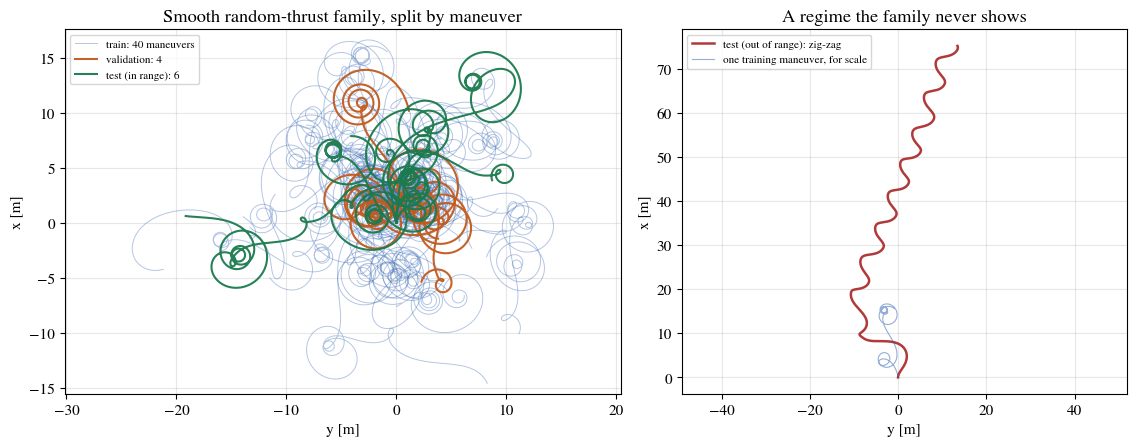

In [2]:
def rand_thrust(rng):
    w = rng.uniform(0.1, 0.5, 3); ph = rng.uniform(0, 2 * np.pi, 3)
    bias = np.array([120.0, 0.0, 0.0]); amp = np.array([60.0, 30.0, 50.0])
    return lambda t, z: bias + amp * np.sin(w * t + ph)

def gen(tau_fn):
    t, Z = vessel.simulate(tau_fn, t_end=T_END, dt=dt, p=p)
    NU = Z[:, 3:]
    TAU = np.array([tau_fn(tk, Zk) for tk, Zk in zip(t, Z)])
    return t, Z, NU, TAU

# --- the split, by maneuver: never split inside a trajectory -------------------
rng = np.random.default_rng(0)
N_TRAIN, N_TEST, N_VAL = 40, 6, 4
train_tau = [rand_thrust(rng) for _ in range(N_TRAIN)]; train   = [gen(tf) for tf in train_tau]   # fit
test_tau  = [rand_thrust(rng) for _ in range(N_TEST)];  test_id = [gen(tf) for tf in test_tau]    # test, in range
val_tau   = [rand_thrust(rng) for _ in range(N_VAL)];   val_id  = [gen(tf) for tf in val_tau]     # choose when to stop
tz, Zz, NUz, TAUz = gen(vessel.zigzag())                                                          # test, out of range
print(f'maneuvers  train={N_TRAIN}  validation={N_VAL}  test-in={N_TEST}  test-out=1 (zig-zag);  {NT} steps each')

# one-step dataset from each split
def one_step_pairs(trajs):
    X, Y = [], []
    for _, _, NU, TAU in trajs:
        X.append(np.hstack([NU[:-1], TAU[:-1]])); Y.append(np.diff(NU, axis=0))
    return np.vstack(X), np.vstack(Y)

Xtr, Ytr = one_step_pairs(train); Xva, Yva = one_step_pairs(val_id); Xte, Yte = one_step_pairs(test_id)
xm, xs = Xtr.mean(0), Xtr.std(0); ym, ys = Ytr.mean(0), Ytr.std(0)                 # standardize on train only
print(f'one-step pairs [nu, tau] -> dnu:  train={len(Xtr)}  validation={len(Xva)}  test-in={len(Xte)}  test-out={NT-1}')

def plot_ddm_vessel_split():
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
    for trs, c, lw, al, tag in [(train, 'C0', 0.7, 0.35, f'train: {N_TRAIN} maneuvers'),
                                (val_id, 'C1', 1.5, 0.95, f'validation: {N_VAL}'),
                                (test_id, 'C2', 1.5, 0.95, f'test (in range): {N_TEST}')]:
        for k, (_, Z, _, _) in enumerate(trs):
            ax[0].plot(Z[:, 1], Z[:, 0], color=c, lw=lw, alpha=al, label=tag if k == 0 else None)
    ax[0].axis('equal'); ax[0].legend(fontsize=8)
    ax[0].set(xlabel='y [m]', ylabel='x [m]', title='Smooth random-thrust family, split by maneuver')
    ax[1].plot(Zz[:, 1], Zz[:, 0], color='C3', lw=1.8, label='test (out of range): zig-zag')
    ax[1].plot(train[0][1][:, 1], train[0][1][:, 0], color='C0', lw=0.8, alpha=0.5, label='one training maneuver, for scale')
    ax[1].axis('equal'); ax[1].legend(fontsize=8)
    ax[1].set(xlabel='y [m]', ylabel='x [m]', title='A regime the family never shows')
    plt.tight_layout()

save_dual(plot_ddm_vessel_split, 'ddm_vessel_split', FIG); plt.show()

The prints confirm the split: **40 / 4 / 6 maneuvers plus the zig-zag, 401 steps each**, giving **16,000 training pairs, 1,600 validation pairs and 2,400 in-range test pairs**; the zig-zag contributes 400 out-of-range pairs. Each pair maps the 6-D input $[\boldsymbol{\nu},\boldsymbol{\tau}]$ to the 3-D velocity increment; `xm,xs` and `ym,ys` are the standardization constants, computed on the **training pairs only**. Left panel of the figure: forty faint blue spirals are the training family, the orange and green ones the validation and test maneuvers drawn from the same family. Right: the zig-zag marches north with heading-triggered reversals — nothing in the family looks like it.

## 2. The surrogate, and aspect 1: one-step accuracy

A small **MLP** — `Linear(6,64)–tanh–Linear(64,64)–tanh–Linear(64,3)`, with the input standardized
and the output de-standardized back to a physical $\Delta\boldsymbol{\nu}$ — realizes the map
$\Delta\boldsymbol{\nu}=f_\theta(\boldsymbol{\nu},\boldsymbol{\tau})$. It is trained by full-batch Adam
(`lr=3e-3`, up to 400 epochs), keeping the parameters with the **lowest validation one-step MSE** (checked every 10 epochs), to minimize the one-step MSE
$\frac1N\sum_n\lVert f_\theta(\boldsymbol{\nu}_n,\boldsymbol{\tau}_n)-\Delta\boldsymbol{\nu}_n\rVert^2$.
On the 6 in-range test maneuvers the parity plot of predicted-vs-true increment sits on
the diagonal — the seductive part: a black box that looks almost perfect at one step.

best validation epoch 400 of 400


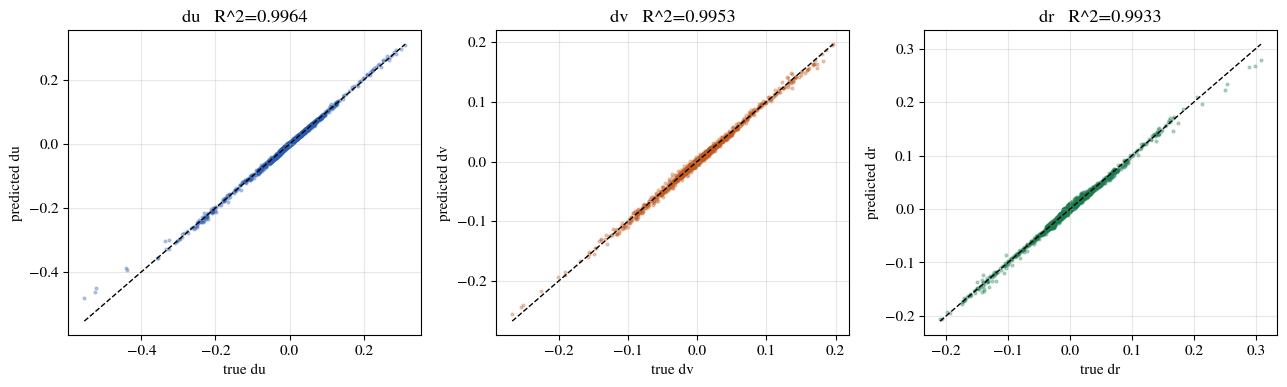

one-step R^2 on the test maneuvers: {'du': 0.9964, 'dv': 0.9953, 'dr': 0.9933}


In [3]:
class Surrogate(nn.Module):
    def __init__(self, xm, xs, ym, ys, width=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(6, width), nn.Tanh(),
                                 nn.Linear(width, width), nn.Tanh(),
                                 nn.Linear(width, 3))
        for nm, v in [('xm', xm), ('xs', xs), ('ym', ym), ('ys', ys)]:
            self.register_buffer(nm, torch.tensor(v))
    def forward(self, nu, tau):
        xn = (torch.cat([nu, tau], -1) - self.xm) / self.xs
        return self.net(xn) * self.ys + self.ym       # physical delta-nu

Xv_t, Yv_t = torch.tensor(Xva), torch.tensor(Yva)
def train_onestep(X, Y, epochs=400, seed=0, every=10):
    "Full-batch Adam on the one-step MSE; keep the parameters with the lowest validation loss."
    torch.manual_seed(seed)
    m = Surrogate(xm, xs, ym, ys)
    Xt = torch.tensor(X); Yt = torch.tensor(Y)
    opt = torch.optim.Adam(m.parameters(), lr=3e-3)
    best, best_ep, best_state = np.inf, 0, None
    for e in range(1, epochs + 1):
        opt.zero_grad()
        loss = ((m(Xt[:, :3], Xt[:, 3:]) - Yt) ** 2).mean(); loss.backward(); opt.step()
        if e % every == 0:
            with torch.no_grad(): lva = float(((m(Xv_t[:, :3], Xv_t[:, 3:]) - Yv_t) ** 2).mean())
            if lva < best: best, best_ep, best_state = lva, e, {k: v.clone() for k, v in m.state_dict().items()}
    m.load_state_dict(best_state); m.best_epoch = best_ep
    return m

model = train_onestep(Xtr, Ytr, epochs=400)
print(f'best validation epoch {model.best_epoch} of 400')

# parity on the in-distribution test maneuvers (touched once)
with torch.no_grad():
    pred = model(torch.tensor(Xte[:, :3]), torch.tensor(Xte[:, 3:])).numpy()
r2 = {}
def plot_ddm_parity():
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    for j, lab in enumerate(['du', 'dv', 'dr']):
        ax[j].scatter(Yte[:, j], pred[:, j], s=4, alpha=0.3, color=f'C{j}')
        lo, hi = Yte[:, j].min(), Yte[:, j].max()
        ax[j].plot([lo, hi], [lo, hi], '--', color=fg(), lw=1)
        r2[lab] = 1 - ((pred[:, j] - Yte[:, j]) ** 2).sum() / ((Yte[:, j] - Yte[:, j].mean()) ** 2).sum()
        ax[j].set(xlabel=f'true {lab}', ylabel=f'predicted {lab}', title=f'{lab}   R^2={r2[lab]:.4f}')
    plt.tight_layout()

save_dual(plot_ddm_parity, 'ddm_parity', FIG)
plt.show()
print('one-step R^2 on the test maneuvers:', {k: round(float(v), 4) for k, v in r2.items()})

The three parity panels — one per component of $\Delta\boldsymbol{\nu}$ — sit essentially on the
diagonal with **$R^2 = 0.9964$ ($\Delta u$), $0.9953$ ($\Delta v$), $0.9933$ ($\Delta r$)**: the
one-step map is captured almost perfectly on the test maneuvers. The best validation epoch is the last one (400): with 16,000 pairs and a small network there is no one-step overfitting to stop. This is exactly the
result that flatters a black box; the next three aspects show that one-step accuracy is the *wrong*
test for a model we intend to roll out. Leaves the trained network in `model`.

## Aspect 2 — Autoregressive rollout drift

Now *use* the model as a simulator: at each step predict $\Delta\boldsymbol{\nu}$, update
$\boldsymbol{\nu}_{n+1}=\boldsymbol{\nu}_n+\Delta\boldsymbol{\nu}$, and advance the pose with the
**known kinematics** $\boldsymbol{\eta}_{n+1}=\boldsymbol{\eta}_n+\Delta t\,\mathbf{R}(\psi_n)\,\boldsymbol{\nu}_{n+1}$ — feeding the network its own output. On the first in-range *test*
maneuver the path stays good, but there is no conservation law to anchor it, so small per-step
errors accumulate into position **drift**. Every autoregressive surrogate suffers this.

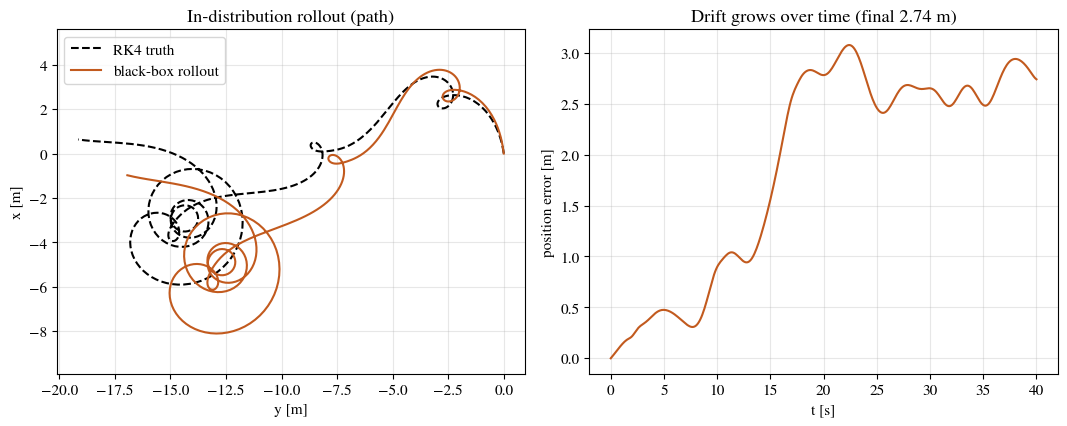

in-distribution rollout: final position error 2.74 m, peak 3.08 m


In [4]:
def rollout(model, tau_fn, n=NT):
    eta = np.zeros(3); nu = np.zeros(3); E = [eta.copy()]; V = [nu.copy()]
    for k in range(n - 1):
        tau = tau_fn(k * dt, np.concatenate([eta, nu]))
        with torch.no_grad():
            dnu = model(torch.tensor(nu)[None], torch.tensor(tau)[None]).numpy()[0]
        nu = nu + dnu
        eta = eta + dt * vessel.rotation(eta[2]) @ nu
        E.append(eta.copy()); V.append(nu.copy())
    return np.array(E), np.array(V)

tau0 = test_tau[0]; t0, Z0, NU0, _ = test_id[0]    # the first in-distribution test maneuver
E, V = rollout(model, tau0)
drift = np.linalg.norm(E[:, :2] - Z0[:, :2], axis=1)

def plot_ddm_rollout_drift():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
    ax[0].plot(Z0[:, 1], Z0[:, 0], '--', color=fg(), label='RK4 truth')
    ax[0].plot(E[:, 1], E[:, 0], 'C1', label='black-box rollout')
    ax[0].axis('equal'); ax[0].legend()
    ax[0].set(xlabel='y [m]', ylabel='x [m]', title='In-distribution rollout (path)')
    ax[1].plot(t0, drift, 'C1'); ax[1].set(xlabel='t [s]', ylabel='position error [m]',
                                           title=f'Drift grows over time (final {drift[-1]:.2f} m)')
    plt.tight_layout()

save_dual(plot_ddm_rollout_drift, 'ddm_rollout_drift', FIG)
plt.show()
print(f'in-distribution rollout: final position error {drift[-1]:.2f} m, peak {drift.max():.2f} m')

Left: the black-box rollout (orange) traces the same looping path as the RK4 truth (dashed), but the loops sit visibly off. Right: the position error grows in waves, **peaking at 3.1 m and ending at 2.74 m** after 40 s — small next to the tens-of-metres path, yet unmistakably growing, and far larger than anything the one-step parity plot suggested. The drift stays bounded here only because the maneuver remains *inside* the training distribution.

## Aspect 3 — The out-of-distribution cliff

The training thrusts were smooth sinusoids. The benchmark's **zig-zag** maneuver
(`vessel.zigzag()`: constant surge $200$ N, yaw moment $\pm120$ flipped whenever the heading crosses
$|\psi|>0.35$ rad) produces sharp, heading-triggered thrust reversals — nothing like the training
family. The *same* model that nailed one-step accuracy is asked to roll this out; on a **log** error
axis its drift is one-to-two orders of magnitude worse than in-distribution. Interpolation is easy;
extrapolation is a cliff.

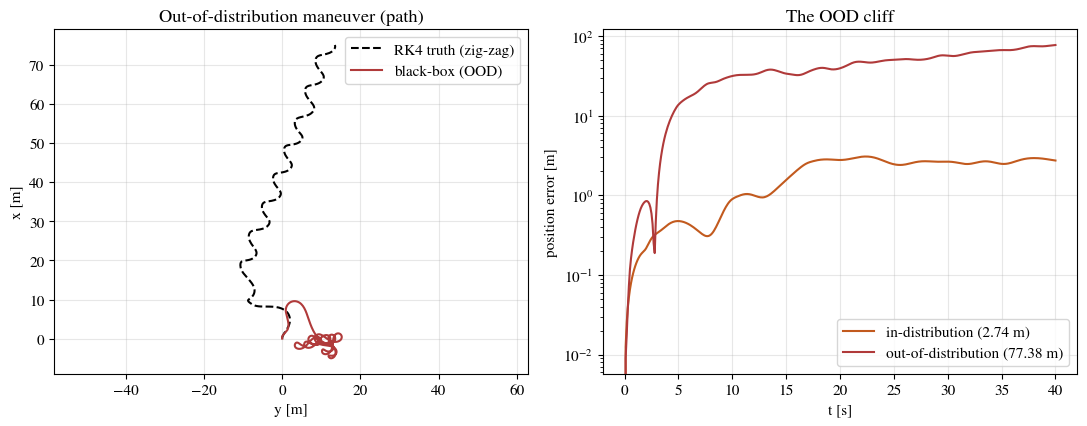

final position error: in-distribution 2.74 m   out-of-distribution 77.38 m


In [5]:
E_id, _ = rollout(model, tau0)
drift_id = np.linalg.norm(E_id[:, :2] - Z0[:, :2], axis=1)

E_ood, _ = rollout(model, vessel.zigzag())
drift_ood = np.linalg.norm(E_ood[:, :2] - Zz[:, :2], axis=1)

def plot_ddm_ood_cliff():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
    ax[0].plot(Zz[:, 1], Zz[:, 0], '--', color=fg(), label='RK4 truth (zig-zag)')
    ax[0].plot(E_ood[:, 1], E_ood[:, 0], 'C3', label='black-box (OOD)')
    ax[0].axis('equal'); ax[0].legend()
    ax[0].set(xlabel='y [m]', ylabel='x [m]', title='Out-of-distribution maneuver (path)')
    ax[1].plot(t0, drift_id, 'C1', label=f'in-distribution ({drift_id[-1]:.2f} m)')
    ax[1].plot(tz, drift_ood, 'C3', label=f'out-of-distribution ({drift_ood[-1]:.2f} m)')
    ax[1].legend(); ax[1].set(xlabel='t [s]', ylabel='position error [m]',
                              title='The OOD cliff', yscale='log')
    plt.tight_layout()

save_dual(plot_ddm_ood_cliff, 'ddm_ood_cliff', FIG)
plt.show()
print(f'final position error: in-distribution {drift_id[-1]:.2f} m   out-of-distribution {drift_ood[-1]:.2f} m')

Left: the RK4 truth (dashed) zig-zags steadily **north** to $x\approx75$ m, while the surrogate (red) collapses into a small knot near the origin — it never advances. Right (log axis): the in-range test drift ends at **2.74 m**, the out-of-range error shoots up within the first few seconds and plateaus around **77 m** (final $77.38$ m) — nearly **$30\times$** worse. Coverage, not quantity, governs a black box.

## Aspect 4 — Does more data help?

Retrain the one-step surrogate on increasingly large pools, `N ∈ {2, 5, 10, 20, 40}` maneuvers, and
measure the **mean rollout error** (position error averaged over the trajectory — less noisy than the
final step) on the 6 in-range test maneuvers and on the same zig-zag. More data should
improve interpolation; the question is whether it touches extrapolation at all.

N= 2  in-dist 4.33 m   OOD 23.48 m


N= 5  in-dist 2.77 m   OOD 37.14 m


N=10  in-dist 1.24 m   OOD 31.97 m


N=20  in-dist 1.76 m   OOD 39.42 m


N=40  in-dist 1.78 m   OOD 38.51 m


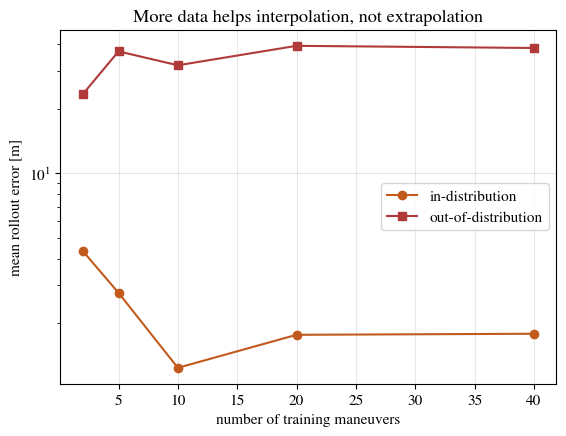

In [6]:
def drift_curve(model, tau_fn, Ztrue):
    E, _ = rollout(model, tau_fn)
    return np.linalg.norm(E[:, :2] - Ztrue[:, :2], axis=1)

def mean_drift(model, tau_fn, Ztrue):           # time-averaged: less noisy than final step
    return float(drift_curve(model, tau_fn, Ztrue).mean())

# evaluation maneuvers: the in-distribution test set, each thrust law alongside its RK4 truth
id_eval = [(tf, Z) for tf, (_, Z, _, _) in zip(test_tau, test_id)]

sizes = [2, 5, 10, 20, 40]
err_id, err_ood = [], []
for N in sizes:
    Xn, Yn = one_step_pairs(train[:N])
    mN = train_onestep(Xn, Yn, epochs=400, seed=1)
    err_id.append(float(np.mean([mean_drift(mN, tf, Z) for tf, Z in id_eval])))
    err_ood.append(mean_drift(mN, vessel.zigzag(), Zz))
    print(f'N={N:2d}  in-dist {err_id[-1]:.2f} m   OOD {err_ood[-1]:.2f} m')

def plot_ddm_data_scaling():
    fig, ax = plt.subplots(figsize=(6.4, 4.6))
    ax.plot(sizes, err_id, 'o-', color='C1', label='in-distribution')
    ax.plot(sizes, err_ood, 's-', color='C3', label='out-of-distribution')
    ax.set(xlabel='number of training maneuvers', ylabel='mean rollout error [m]',
           title='More data helps interpolation, not extrapolation', yscale='log')
    ax.legend()

save_dual(plot_ddm_data_scaling, 'ddm_data_scaling', FIG)
plt.show()

The printed sweep and the log-scale figure agree: the **in-range** error falls from **4.3 m at $N=2$** to **1.2 m at $N=10$** and then plateaus around **1.8 m** (the rise from 10 to 20 maneuvers is run-to-run noise), while the **out-of-range** zig-zag error stays pinned at **23–39 m** for every pool size. No amount of smooth-maneuver data teaches the sharp reversals: **data fixes interpolation, not extrapolation.**

## Aspect 5 — A partial fix: fine-tune on rollouts, not single steps

The drift is a train/test mismatch — trained on *one* step but used for *many*. Starting from the
one-step `model`, **fine-tune on a $k$-step rollout** ($k=12$): unroll 12 steps from random windows
of the pool and penalize the accumulated error
$\frac1k\sum_{j=1}^{k}\lVert\hat{\boldsymbol{\nu}}_{n+j}-\boldsymbol{\nu}_{n+j}\rVert^2$, which targets
the very quantity used at test time. This should reduce drift but cannot cure the OOD cliff — that is
structural, not an objective-design issue.

mean rollout error  one-step 0.89 m   multi-step 0.78 m


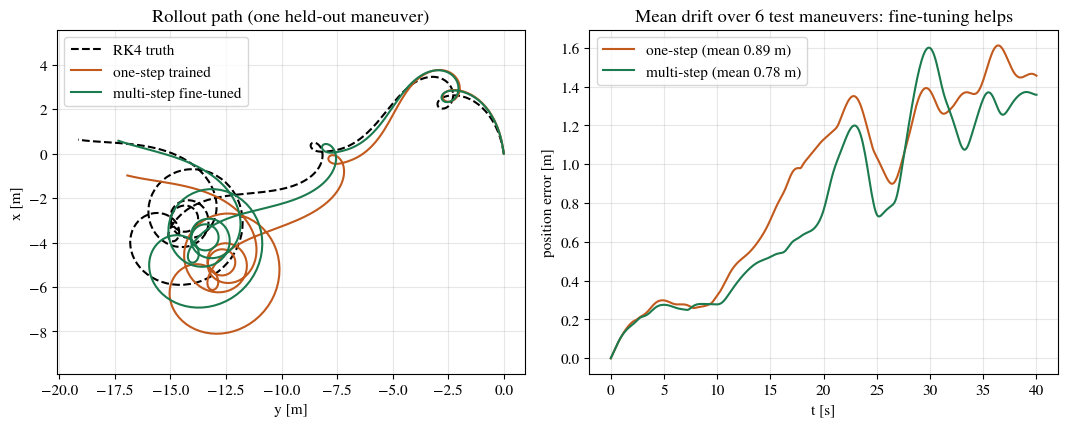

In [7]:
# stack the pool into (N, T, 3) tensors for windowed multi-step training
NUs = torch.tensor(np.stack([tr[2] for tr in train]))    # (N, T, 3)
TAUs = torch.tensor(np.stack([tr[3] for tr in train]))

def finetune_multistep(base, epochs=400, k=12, nb=512, seed=0, lr=1e-3):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    m = Surrogate(xm, xs, ym, ys); m.load_state_dict(base.state_dict())  # start from one-step
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    N, T, _ = NUs.shape
    for e in range(epochs):
        ti = torch.randint(0, N, (nb,), generator=g)
        si = torch.randint(0, T - k - 1, (nb,), generator=g)
        nu = NUs[ti, si]
        loss = 0.0
        for j in range(k):
            nu = nu + m(nu, TAUs[ti, si + j])
            loss = loss + ((nu - NUs[ti, si + j + 1]) ** 2).mean()
        opt.zero_grad(); (loss / k).backward(); opt.step()
    return m

model_ms = finetune_multistep(model, epochs=400, k=12)

# average drift over time across the held-out in-distribution maneuvers
D_os = np.mean([drift_curve(model,    tf, Z) for tf, Z in id_eval], axis=0)
D_ms = np.mean([drift_curve(model_ms, tf, Z) for tf, Z in id_eval], axis=0)
print(f'mean rollout error  one-step {D_os.mean():.2f} m   multi-step {D_ms.mean():.2f} m')

tf0, Zr = id_eval[0]
E_os, _ = rollout(model, tf0); E_ms, _ = rollout(model_ms, tf0)

def plot_ddm_multistep():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
    ax[0].plot(Zr[:, 1], Zr[:, 0], '--', color=fg(), label='RK4 truth')
    ax[0].plot(E_os[:, 1], E_os[:, 0], 'C1', label='one-step trained')
    ax[0].plot(E_ms[:, 1], E_ms[:, 0], 'C2', label='multi-step fine-tuned')
    ax[0].axis('equal'); ax[0].legend()
    ax[0].set(xlabel='y [m]', ylabel='x [m]', title='Rollout path (one held-out maneuver)')
    ax[1].plot(t0, D_os, 'C1', label=f'one-step (mean {D_os.mean():.2f} m)')
    ax[1].plot(t0, D_ms, 'C2', label=f'multi-step (mean {D_ms.mean():.2f} m)')
    ax[1].legend(); ax[1].set(xlabel='t [s]', ylabel='position error [m]',
                              title=f'Mean drift over {len(id_eval)} test maneuvers: fine-tuning helps')
    plt.tight_layout()

save_dual(plot_ddm_multistep, 'ddm_multistep', FIG)
plt.show()

Averaged over the 6 test maneuvers, the mean rollout error drops from **0.89 m (one-step)** to **0.78 m (multi-step)** — about a 12% reduction. In the figure the multi-step path (green) hugs the RK4 truth (dashed) more tightly than the one-step path (orange), and its mean error curve stays below the one-step curve over most of the horizon. Fine-tuning softens the drift; it does nothing for the out-of-range cliff — confirming the drift is partly an objective-design problem while the cliff is not.

**Lesson.** A black-box surrogate is accurate at one step, drifts under rollout, and
falls off a cliff out of distribution; more data buys interpolation but not extrapolation,
and rollout-aware training only softens the drift. The remaining error is information the data
does not contain: the model has no notion of momentum or damping, and the zig-zag regime never
appears in the training set.